In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

from src.data_loader import load_all, MODELS_DIR, REPORTS_DIR, FIGURES_DIR
from src.preprocessing import split_data

results = pd.read_csv(REPORTS_DIR / "results.csv")
display(results.drop(columns="best_params").round(3))

,dataset,model,cv_auc,accuracy,precision,recall,f1,roc_auc
0,heart,LogisticRegression,0.911,0.885,0.839,0.929,0.881,0.961
1,heart,SVM,0.902,0.852,0.788,0.929,0.852,0.945
2,heart,RandomForest,0.899,0.885,0.818,0.964,0.885,0.952
3,heart,XGBoost,0.882,0.902,0.844,0.964,0.900,0.939
4,breast,LogisticRegression,0.995,0.974,0.976,0.952,0.964,0.995
5,breast,SVM,0.995,0.991,1.000,0.976,0.988,0.996
6,breast,RandomForest,0.990,0.965,0.975,0.929,0.951,0.998
7,breast,XGBoost,0.995,0.965,1.000,0.905,0.950,0.994
8,diabetes,LogisticRegression,0.845,0.708,0.571,0.667,0.615,0.810
9,diabetes,SVM,0.844,0.727,0.594,0.704,0.644,0.806


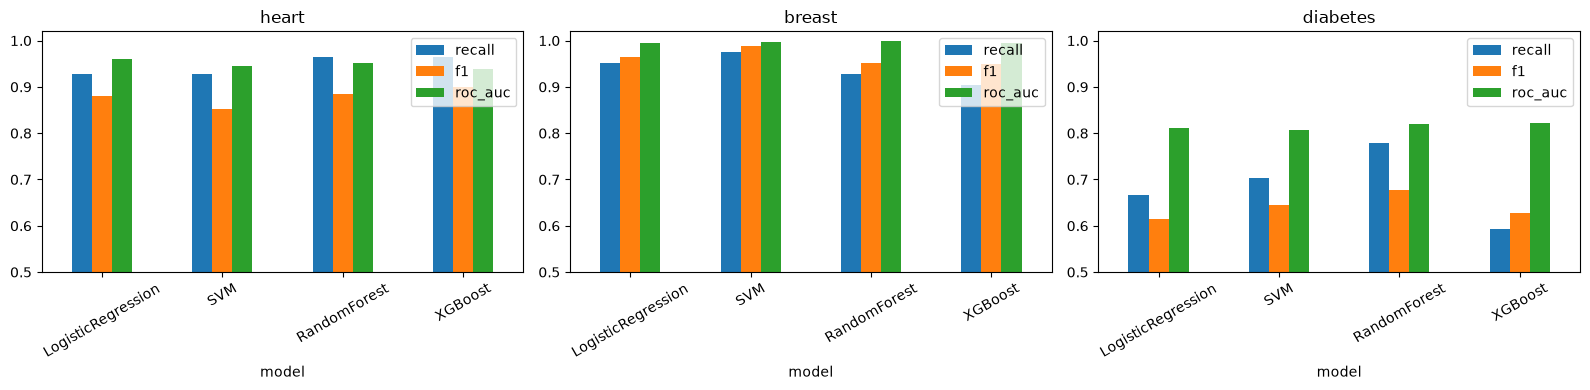

In [2]:
metrics = ["recall", "f1", "roc_auc"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, ds in zip(axes, results["dataset"].unique()):
    results[results.dataset == ds].set_index("model")[metrics].plot(kind="bar", ax=ax)
    ax.set_title(ds)
    ax.set_ylim(0.5, 1.02)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_comparison.png", dpi=150)
plt.show()

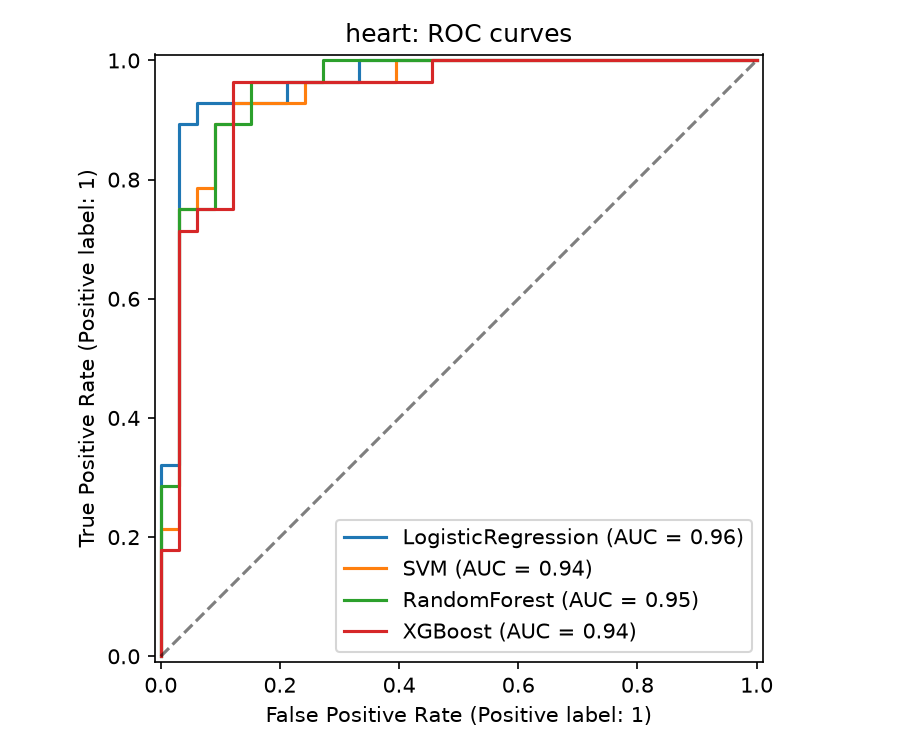

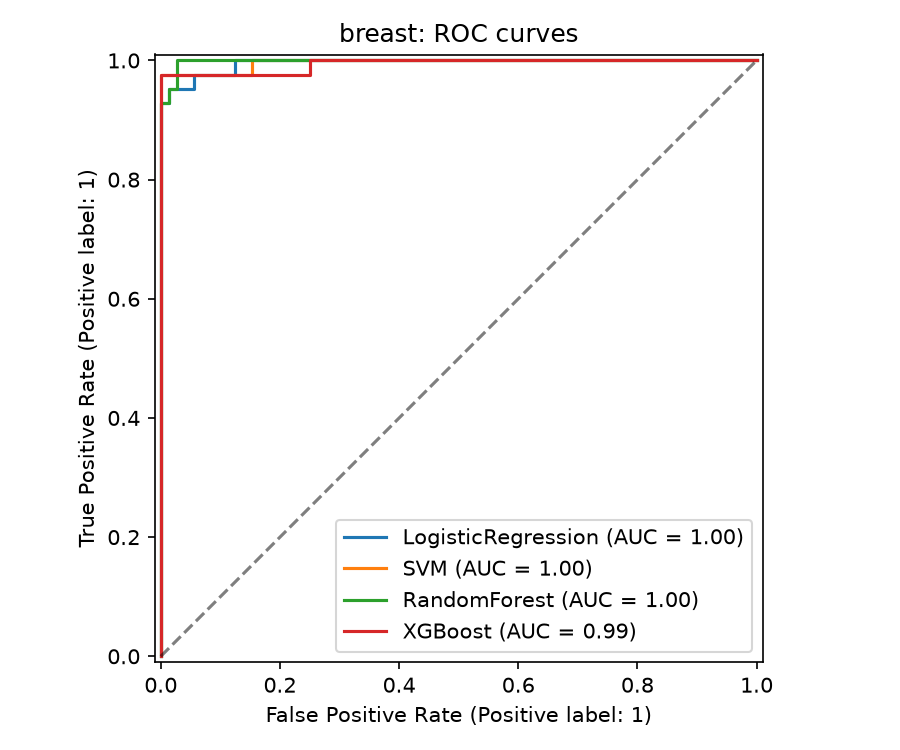

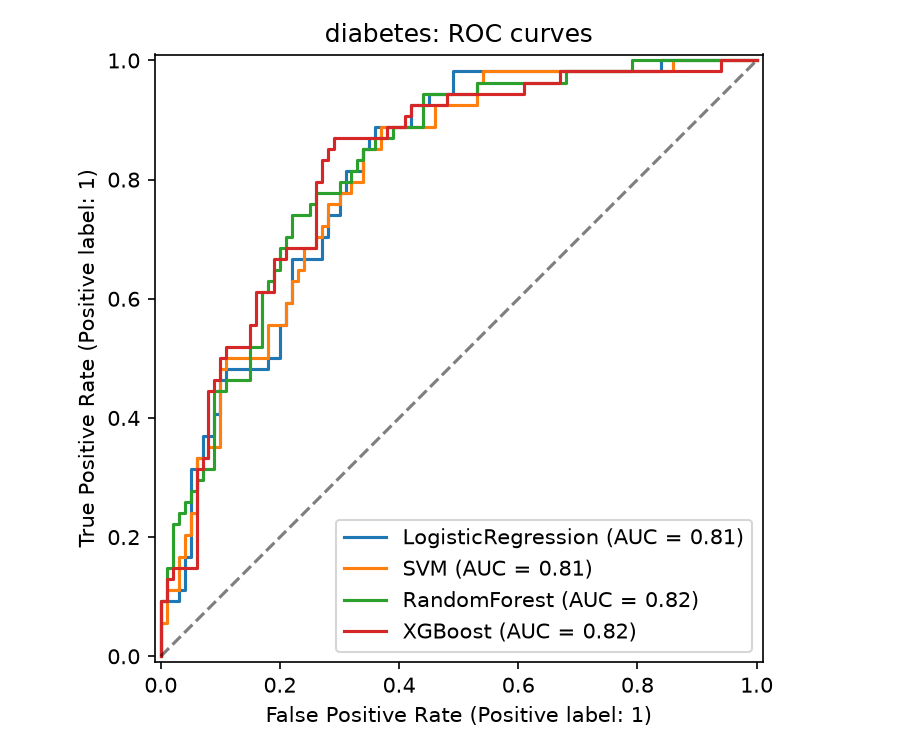

In [3]:
for ds in ["heart", "breast", "diabetes"]:
    display(Image(filename=str(FIGURES_DIR / f"{ds}_roc.png")))

d:\disease_prediction\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


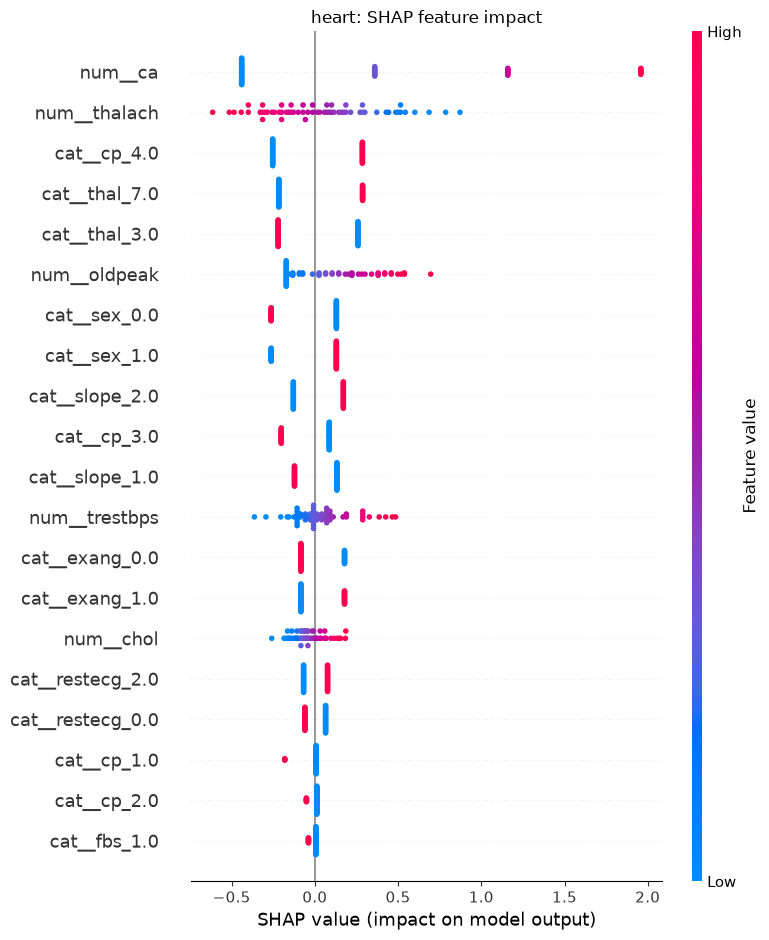

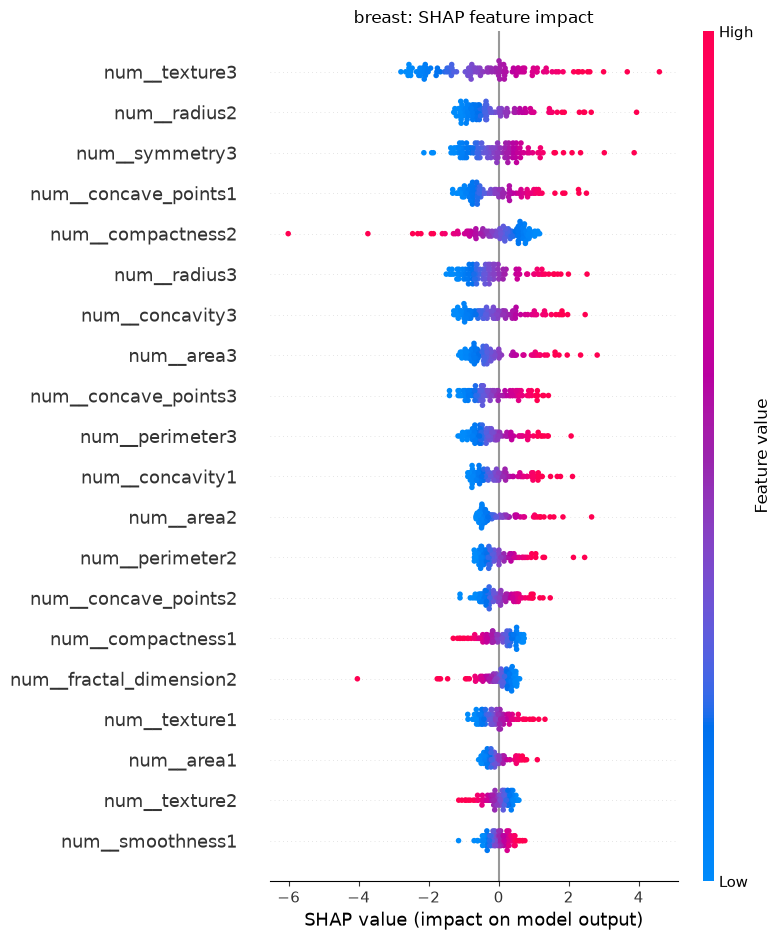

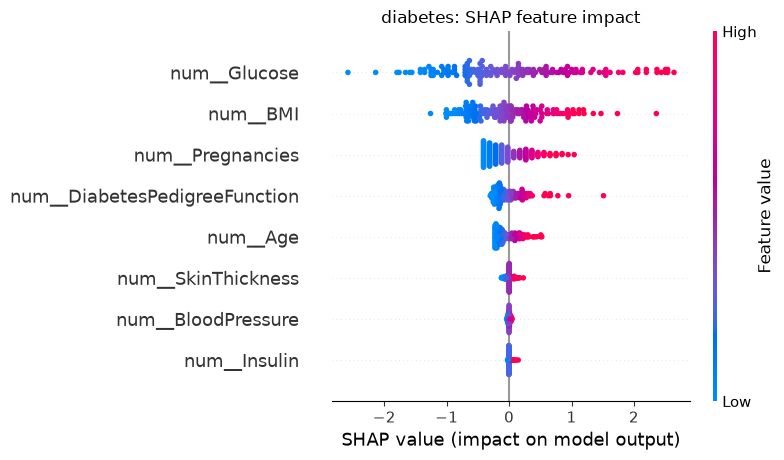

In [4]:
import shap
datasets = load_all()

for ds in ["heart", "breast", "diabetes"]:
    X, y = datasets[ds]
    X_train, X_test, y_train, y_test = split_data(X, y)
    pipe = joblib.load(MODELS_DIR / f"{ds}_best.joblib")

    prep, clf = pipe.named_steps["prep"], pipe.named_steps["clf"]
    names = prep.get_feature_names_out()
    Xt_train = pd.DataFrame(prep.transform(X_train), columns=names)
    Xt_test = pd.DataFrame(prep.transform(X_test), columns=names)

    # Linear explainer works for Logistic Regression; use shap.Explainer for the rest
    if clf.__class__.__name__ == "LogisticRegression":
        explainer = shap.LinearExplainer(clf, Xt_train)
        sv = explainer.shap_values(Xt_test)
    else:
        sv = shap.Explainer(clf.predict_proba, Xt_train)(Xt_test).values[:, :, 1]

    plt.title(f"{ds}: SHAP feature impact")
    shap.summary_plot(sv, Xt_test, show=False)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{ds}_shap.png", dpi=150, bbox_inches="tight")
    plt.show()